# Espaço latente do Autoencoder: PCA e t-SNE
## Detecção de anomalias com Autoencoder — Issue #7

**Responsável:** Luiz Wessel (`Wessel2007`). **Etapa da arquitetura:** 7. Extração das representações latentes.

O Autoencoder comprime cada imagem de 784 pixels em um vetor de `latent_dim = 16` números (o gargalo)
e precisa reconstruir a imagem a partir dele. **Nenhum rótulo é usado no treino**: o alvo é a própria imagem.
Se, mesmo assim, imagens da mesma classe ficarem próximas no espaço latente, a rede aprendeu estrutura
dos dados sozinha. Esse é o argumento central deste notebook.

**Perguntas:**
1. As classes formam grupos no espaço latente?
2. Onde cai a classe anômala, que o modelo **nunca viu**: separada ou misturada com classes parecidas?

**Protocolo.** Usamos os dois checkpoints da issue #5 (`models/ae_bag.pt` e `models/ae_sandal.pt`), cada um
treinado sem a sua classe anômala. Os vetores latentes vêm do **teste oficial** (10.000 imagens, 1.000 por classe).
Aqui o teste serve só para **visualizar e diagnosticar**: nenhuma decisão do detector (modelo, limiar) é tomada
com base nestas figuras. Os rótulos entram somente para **colorir** os pontos e medir a mistura entre classes.

### 1. Ambiente, configuração e checkpoints

Os checkpoints não são versionados (`models/` está no `.gitignore`). Se não existirem, treine os dois cenários antes
(instruções no README). Pesos treinados em outra máquina podem diferir um pouco: seeds fixas não garantem resultados
idênticos em todo hardware. Por isso, os números citados no texto são aproximados, e os valores exatos aparecem nas saídas das células.

In [1]:
%matplotlib inline
from dataclasses import replace
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from autoencoder import visualize
from autoencoder.data import CLASS_NAMES, load_config, load_splits, make_dataloaders
from autoencoder.inference import SCENARIOS, encode_dataset, load_trained_model
from autoencoder.reproducibility import set_seed

ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "configs/default.yaml").is_file() and (p / "pyproject.toml").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Abra o notebook dentro do repositório do projeto.")

CONFIG_PATH = ROOT / "configs/default.yaml"
base_config = load_config(CONFIG_PATH)
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = base_config.seed
set_seed(SEED)

missing = [ckpt for _, ckpt in SCENARIOS.values() if not (ROOT / ckpt).is_file()]
if missing:
    raise FileNotFoundError(
        f"Checkpoints ausentes: {missing}. Treine antes, na raiz do projeto:\n"
        "  python scripts/train_cenarios.py --scenario bag\n"
        "  python scripts/train_cenarios.py --scenario sandal")

def show_and_save(fig, filename):
    """Exibe no notebook e salva em reports/figures/ (fundo branco, para slides)."""
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def load_scenario(name):
    """Mesma divisão de dados do treino e da avaliação, com a classe anômala do cenário."""
    anomaly_class, checkpoint = SCENARIOS[name]
    config = replace(base_config, anomaly_class=anomaly_class)
    splits = load_splits(config)
    loaders = make_dataloaders(splits, config.batch_size, config.num_workers)
    model = load_trained_model(CONFIG_PATH, ROOT / checkpoint)
    return anomaly_class, splits, loaders, model

print(f"Seed: {SEED} | latent_dim: {load_trained_model(CONFIG_PATH, ROOT / SCENARIOS['bag'][1]).latent_dim}")
print("Cenários:", {name: CLASS_NAMES[c] for name, (c, _) in SCENARIOS.items()})

Seed: 42 | latent_dim: 16
Cenários: {'bag': 'Bag', 'sandal': 'Sandal'}


### 2. Extração dos vetores latentes com `encode()`

`encode_dataset()` coloca o modelo em `eval()`, desliga o gradiente e aplica `model.encode()` lote a lote.
O loader de teste não embaralha, então a linha `i` da matriz latente corresponde à imagem `i` do teste.

In [2]:
scenarios = {}
for name in SCENARIOS:
    anomaly_class, splits, loaders, model = load_scenario(name)
    encoded = encode_dataset(model, loaders["test"])
    # Mesma ordem do split: os rótulos devolvidos pelo loader batem com os do arquivo oficial.
    np.testing.assert_array_equal(encoded["labels"], splits.test.labels)
    scenarios[name] = {
        "anomaly_class": anomaly_class,
        "latent": encoded["latent"],
        "labels": encoded["labels"],
        "pixels": splits.test.images,
    }
    z = encoded["latent"]
    print(f"[{name}] anomalia = {CLASS_NAMES[anomaly_class]} | latentes {z.shape} | "
          f"média {z.mean():+.3f}, desvio {z.std():.3f}, mín {z.min():+.2f}, máx {z.max():+.2f}")

[bag] anomalia = Bag | latentes (10000, 16) | média -0.005, desvio 3.806, mín -18.22, máx +16.85
[sandal] anomalia = Sandal | latentes (10000, 16) | média +0.149, desvio 3.882, mín -17.03, máx +16.01


### 3. PCA × t-SNE: o que cada projeção mostra (e o que não mostra)

O espaço latente tem 16 dimensões; para desenhá-lo precisamos projetar em 2D. As duas técnicas respondem perguntas diferentes.

| | **PCA** | **t-SNE** |
|---|---|---|
| Tipo | **Linear**: gira os eixos e mantém as 2 direções de maior variância | **Não linear**: posiciona os pontos para manter os mesmos vizinhos |
| Preserva | A **variância global** e a geometria "grande" (direções, alongamentos) | A **vizinhança local**: quem está perto de quem |
| Perde | Tudo o que está fora das 2 primeiras componentes (a variância explicada mostra quanto sobra) | Escalas e distâncias globais |
| Determinístico? | Sim | Depende da seed e da `perplexity` (≈ número efetivo de vizinhos) |
| Custo | Rápido: usamos as 10.000 imagens | Quadrático: usamos uma amostra estratificada de 3.000 |

**Por que não interpretar distâncias entre grupos no t-SNE.** O t-SNE só penaliza erros na vizinhança: ele quer que
vizinhos no espaço original continuem vizinhos no plano. Para pontos que já são distantes, qualquer distância grande
"serve", então a separação entre dois grupos no desenho não mede o quanto eles são diferentes. Além disso, no plano ele
usa uma distribuição de cauda pesada (t de Student), que **exagera os vazios** entre grupos, e ele normaliza a densidade
local, então o **tamanho** de um grupo também não diz nada. Mudar a seed ou a `perplexity` reorganiza a posição das ilhas.
O que se pode ler com segurança: **se um grupo é coeso e com quem ele se mistura**.

**Por que não basta olhar o PCA.** Duas componentes podem explicar só parte da variância; pontos sobrepostos no plano
podem estar separados nas dimensões descartadas. Por isso a seção 6 mede a mistura **nas 16 dimensões originais**,
sem projeção.

### 4. PCA do espaço latente (teste completo, n = 10.000)

À esquerda, cores por classe (paleta `tab10`); à direita, normais em cinza e a anomalia em magenta, desenhada por cima.

[bag] variância latente explicada pelas 2 componentes: 65.1%
[sandal] variância latente explicada pelas 2 componentes: 58.3%


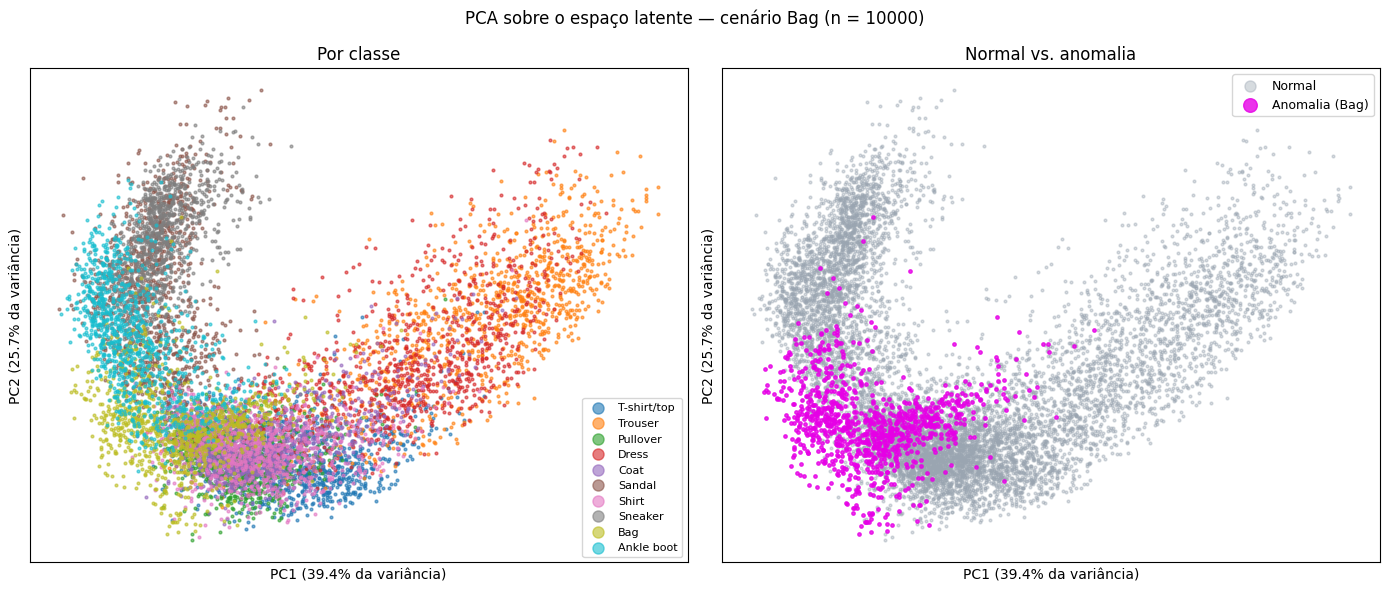

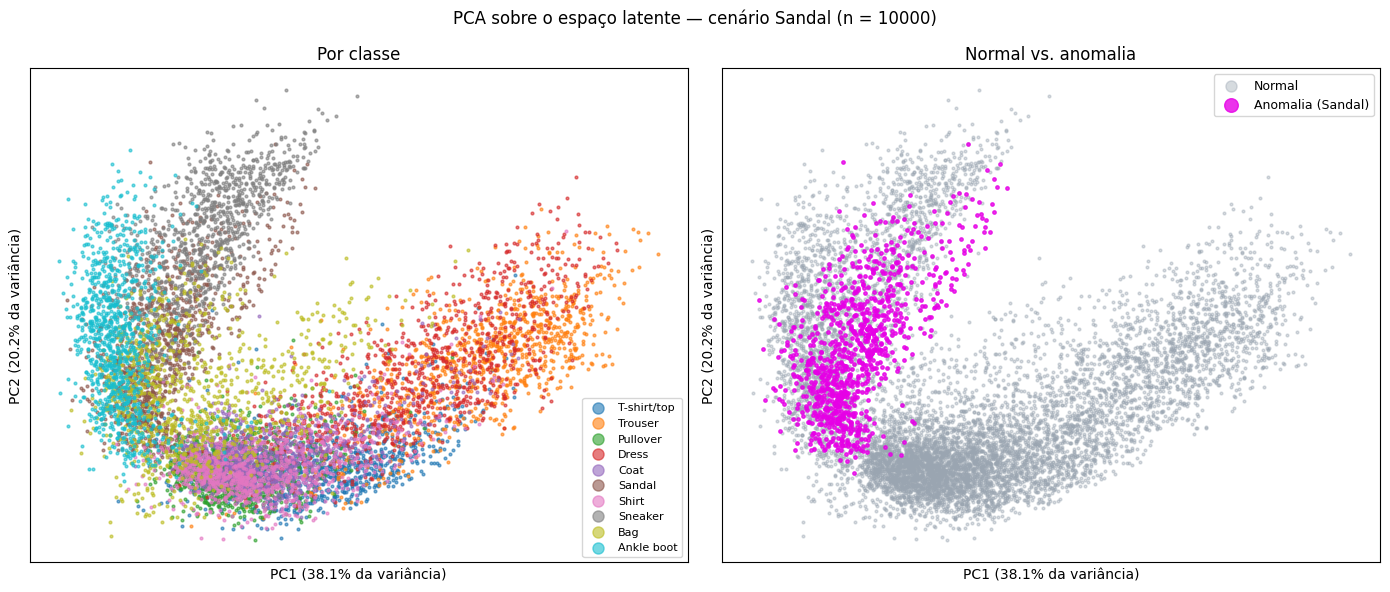

In [3]:
for name, s in scenarios.items():
    coords, variance = visualize.project_pca(s["latent"], seed=SEED)
    s["pca_variance"] = variance
    axis = (f"PC1 ({variance[0]:.1%} da variância)", f"PC2 ({variance[1]:.1%} da variância)")
    fig = visualize.plot_projection_panel(
        coords, s["labels"], s["anomaly_class"], "PCA",
        f"o espaço latente — cenário {CLASS_NAMES[s['anomaly_class']]}", axis_labels=axis)
    show_and_save(fig, f"latent_pca_{name}.png")
    print(f"[{name}] variância latente explicada pelas 2 componentes: {variance.sum():.1%}")

### 5. t-SNE do espaço latente (amostra estratificada, n = 3.000)

A amostra mantém a proporção de cada classe (300 por classe, incluindo 300 anômalas). O espaço latente já tem
16 dimensões, então ele vai direto ao t-SNE, sem a redução por PCA usada para os pixels.

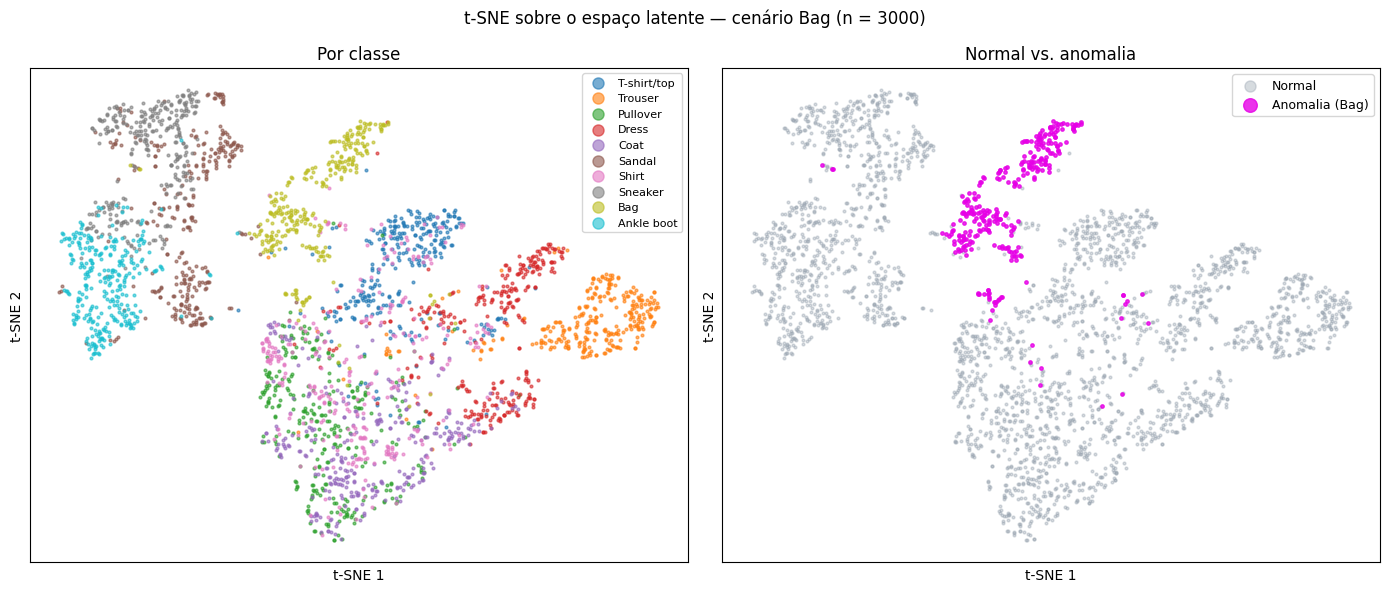

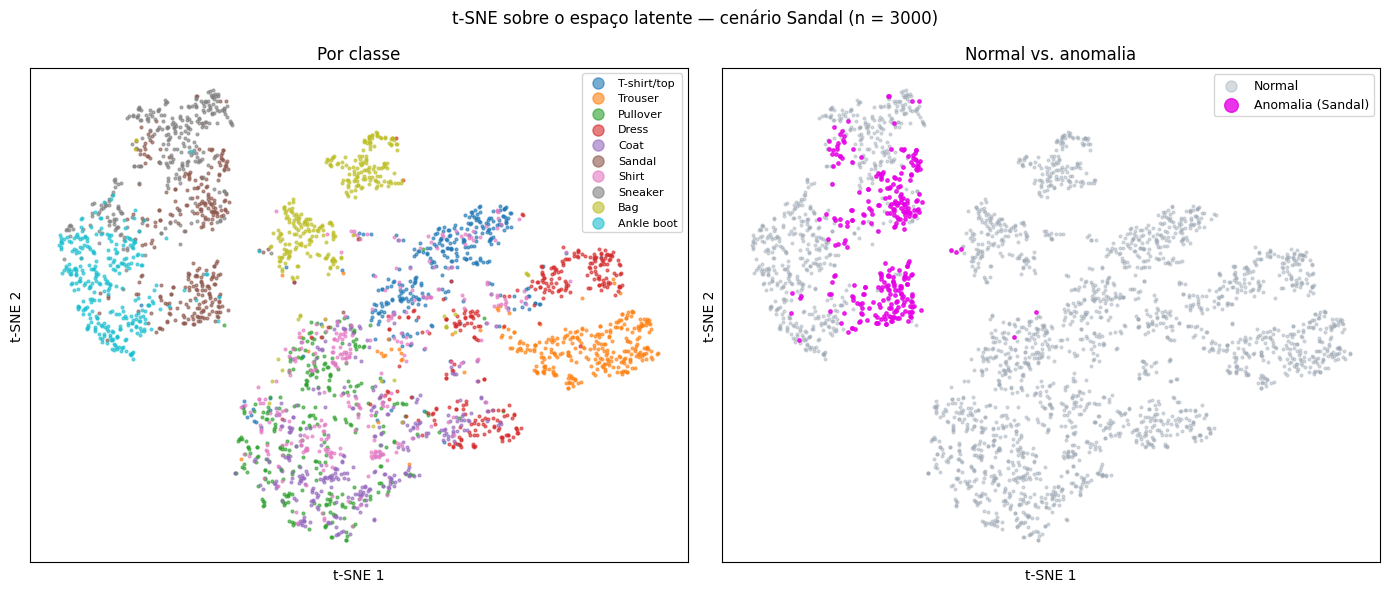

In [4]:
TSNE_SAMPLES, PERPLEXITY = 3000, 30.0
for name, s in scenarios.items():
    sample = visualize.stratified_sample(s["labels"], TSNE_SAMPLES, seed=SEED)
    coords = visualize.project_tsne(s["latent"][sample], perplexity=PERPLEXITY, seed=SEED)
    fig = visualize.plot_projection_panel(
        coords, s["labels"][sample], s["anomaly_class"], "t-SNE",
        f"o espaço latente — cenário {CLASS_NAMES[s['anomaly_class']]}")
    show_and_save(fig, f"latent_tsne_{name}.png")

### 6. Medindo a mistura sem projeção: vizinhos nas 16 dimensões

Para cada imagem do teste, buscamos as **k = 10 imagens mais próximas** (distância euclidiana) no espaço latente completo
e anotamos a classe delas. A linha *i* da matriz abaixo é a fração dos vizinhos de pontos da classe *i* que pertencem
a cada classe:

- **diagonal** = pureza da vizinhança: quanto a classe forma um grupo próprio;
- **linha da anomalia** (marcada com `*`) = onde a classe nunca vista caiu, e com quais classes se mistura.

A mesma medida sobre os **pixels brutos** (784 dimensões) serve de base de comparação: ela mostra se a compressão
para 16 números preservou, perdeu ou reforçou a organização por classe.

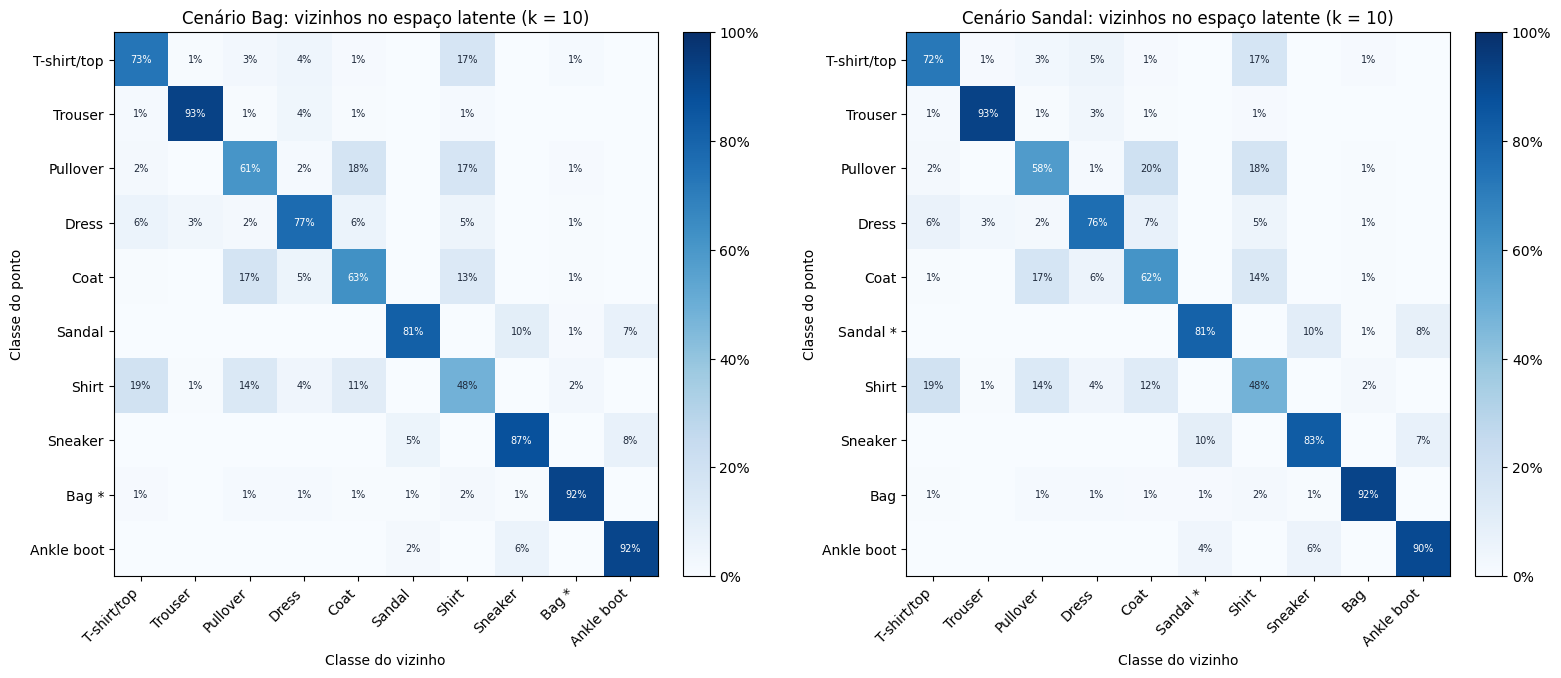

| Cenário | Classe | Pureza nos pixels | Pureza no latente |
|---|---|---:|---:|
| bag | T-shirt/top | 75.5% | 73.2% |
| bag | Trouser | 93.6% | 92.6% |
| bag | Pullover | 61.6% | 60.6% |
| bag | Dress | 74.7% | 77.0% |
| bag | Coat | 60.1% | 62.8% |
| bag | Sandal | 68.5% | 81.4% |
| bag | Shirt | 48.9% | 48.3% |
| bag | Sneaker | 91.1% | 87.2% |
| bag | Bag (anômala) | 89.9% | 91.8% |
| bag | Ankle boot | 93.2% | 91.6% |
| sandal | T-shirt/top | 75.5% | 72.2% |
| sandal | Trouser | 93.6% | 92.7% |
| sandal | Pullover | 61.6% | 58.0% |
| sandal | Dress | 74.7% | 76.1% |
| sandal | Coat | 60.1% | 61.5% |
| sandal | Sandal (anômala) | 68.5% | 80.8% |
| sandal | Shirt | 48.9% | 47.8% |
| sandal | Sneaker | 91.1% | 83.1% |
| sandal | Bag | 89.9% | 91.9% |
| sandal | Ankle boot | 93.2% | 90.1% |

In [5]:
K = 10
fig, axes = plt.subplots(1, 2, figsize=(16, 6.8))
rows = []
for ax, (name, s) in zip(axes, scenarios.items()):
    anomaly = s["anomaly_class"]
    latent_matrix, classes = visualize.neighbor_class_matrix(s["latent"], s["labels"], k=K)
    pixel_matrix, _ = visualize.neighbor_class_matrix(s["pixels"], s["labels"], k=K, classes=classes)
    s["latent_neighbors"], s["pixel_neighbors"], s["classes"] = latent_matrix, pixel_matrix, classes
    visualize.plot_neighbor_matrix(
        latent_matrix, classes, f"Cenário {CLASS_NAMES[anomaly]}: vizinhos no espaço latente (k = {K})",
        ax=ax, anomaly_class=anomaly)
    for i, c in enumerate(classes):
        rows.append((name, CLASS_NAMES[c] + (" (anômala)" if c == anomaly else ""),
                     pixel_matrix[i, i], latent_matrix[i, i]))
fig.tight_layout()
show_and_save(fig, f"latent_vizinhos_k{K}.png")

table = ["| Cenário | Classe | Pureza nos pixels | Pureza no latente |", "|---|---|---:|---:|"]
table += [f"| {n} | {c} | {p:.1%} | {l:.1%} |" for n, c, p, l in rows]
display(Markdown("\n".join(table)))

In [6]:
def top_mixtures(row, classes, own, n=3):
    order = [i for i in np.argsort(-row) if classes[i] != own and row[i] > 0][:n]
    return ", ".join(f"{CLASS_NAMES[classes[i]]} {row[i]:.1%}" for i in order)

for name, s in scenarios.items():
    a, classes = s["anomaly_class"], s["classes"]
    i = list(classes).index(a)
    print(f"[{name}] anomalia {CLASS_NAMES[a]}")
    print(f"  pixels : {s['pixel_neighbors'][i, i]:.1%} dos vizinhos também são {CLASS_NAMES[a]}; "
          f"mistura: {top_mixtures(s['pixel_neighbors'][i], classes, a)}")
    print(f"  latente: {s['latent_neighbors'][i, i]:.1%} dos vizinhos também são {CLASS_NAMES[a]}; "
          f"mistura: {top_mixtures(s['latent_neighbors'][i], classes, a)}")
    print(f"  pureza média das 10 classes: pixels {np.diag(s['pixel_neighbors']).mean():.1%} | "
          f"latente {np.diag(s['latent_neighbors']).mean():.1%}")

[bag] anomalia Bag
  pixels : 89.9% dos vizinhos também são Bag; mistura: Shirt 2.6%, Pullover 2.3%, Coat 1.4%
  latente: 91.8% dos vizinhos também são Bag; mistura: Shirt 2.2%, Pullover 1.4%, Dress 1.3%
  pureza média das 10 classes: pixels 75.7% | latente 76.7%
[sandal] anomalia Sandal
  pixels : 68.5% dos vizinhos também são Sandal; mistura: Sneaker 18.3%, Ankle boot 11.0%, T-shirt/top 0.9%
  latente: 80.8% dos vizinhos também são Sandal; mistura: Sneaker 10.3%, Ankle boot 8.0%, Bag 0.7%
  pureza média das 10 classes: pixels 75.7% | latente 75.4%


### 7. Análise

**As classes formam grupos?** Sim, mas não todas da mesma forma, e isso foi aprendido **sem nenhum rótulo**.

- **Trouser, Sneaker, Ankle boot e Bag** formam grupos bem definidos: entre ≈ 83% e ≈ 93% dos vizinhos são da mesma
  classe, e no t-SNE aparecem como ilhas coesas.
- As **peças de parte superior** (T-shirt/top, Pullover, Coat e principalmente **Shirt**) se misturam: a pureza do Shirt
  fica perto de 50%. Isso confirma a hipótese da EDA (#3) de que essas classes são visualmente parecidas. Para o
  Autoencoder, que só precisa reconstruir a forma, uma camisa e um casaco de silhueta igual são quase a mesma imagem.
- Comprimindo 784 pixels em **16 números**, a pureza média ficou praticamente igual à dos pixels brutos (≈ 76%). A rede
  manteve a organização dos dados com 49 vezes menos números. Os **calçados ficaram mais bem separados** no latente:
  a Sandal sobe de ≈ 69% de pureza nos pixels para ≈ 81% no latente, nos dois cenários.

**Onde cai a classe anômala?**

- **Bag (cenário "fácil"):** forma um **grupo próprio**, com ≈ 92% de vizinhos Bag; no t-SNE aparece em ilhas separadas
  das roupas, com poucos pontos espalhados entre as blusas. A pouca mistura que sobra é com Shirt, Pullover e Dress
  (formas retangulares, sem mangas aparentes). No PCA, as bolsas se sobrepõem à região das
  blusas: as 2 componentes explicam só ≈ 65% da variância do latente, e essa sobreposição **é um efeito da projeção**,
  não da representação, como a medida de vizinhos em 16 dimensões mostra.
- **Sandal (cenário "difícil"):** também fica majoritariamente junta (≈ 81% de vizinhos Sandal), mas **dentro da região
  dos calçados**: os vizinhos que não são sandálias são quase todos **Sneaker** (≈ 10%) e **Ankle boot** (≈ 8%); roupas
  somam menos de 1%. É a mistura com "classes parecidas" prevista pela EDA.

**O ponto mais importante para a apresentação:** a anomalia ficar separada no espaço latente **não garante** que ela será
detectada. O detector não usa a posição no latente; ele usa o **erro de reconstrução**. A Sandal está separada no
latente, mas o decodificador só aprendeu a desenhar calçados normais, e muitas sandálias são reconstruídas como tênis com
erro baixo (ver `04_reconstructions.ipynb`, issue #8). Já a Bag é diferente das roupas **e** mal reconstruída, por isso é
mais fácil. Usar a distância no espaço latente como escore de anomalia seria uma alternativa interessante, mas avaliá-la
exigiria escolher o método sem consultar este teste.

### 8. Resumo reproduzível

Os números acima são gravados em `reports/latent_space_summary.json` para o relatório e a apresentação.

In [7]:
summary = {
    "fonte": "encode() sobre o teste oficial (10.000 imagens)",
    "seed": SEED,
    "k_vizinhos": K,
    "tsne": {"amostras": TSNE_SAMPLES, "perplexity": PERPLEXITY},
    "cenarios": {},
}
for name, s in scenarios.items():
    a, classes = s["anomaly_class"], s["classes"]
    i = list(classes).index(a)
    summary["cenarios"][name] = {
        "classe_anomala": CLASS_NAMES[a],
        "latent_dim": int(s["latent"].shape[1]),
        "pca_variancia_explicada": [round(float(v), 4) for v in s["pca_variance"]],
        "pureza_por_classe_latente": {CLASS_NAMES[c]: round(float(s["latent_neighbors"][j, j]), 4) for j, c in enumerate(classes)},
        "pureza_por_classe_pixels": {CLASS_NAMES[c]: round(float(s["pixel_neighbors"][j, j]), 4) for j, c in enumerate(classes)},
        "vizinhos_da_anomalia_latente": {CLASS_NAMES[c]: round(float(v), 4) for c, v in zip(classes, s["latent_neighbors"][i]) if v > 0},
        "vizinhos_da_anomalia_pixels": {CLASS_NAMES[c]: round(float(v), 4) for c, v in zip(classes, s["pixel_neighbors"][i]) if v > 0},
        "figuras": [f"reports/figures/latent_pca_{name}.png", f"reports/figures/latent_tsne_{name}.png"],
    }
summary["figura_vizinhos"] = f"reports/figures/latent_vizinhos_k{K}.png"
path = ROOT / "reports/latent_space_summary.json"
path.write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("Resumo salvo em", path.relative_to(ROOT).as_posix())
print("Figuras:", sorted(p.name for p in FIGURES.glob("latent_*.png")))

Resumo salvo em reports/latent_space_summary.json
Figuras: ['latent_pca_bag.png', 'latent_pca_sandal.png', 'latent_tsne_bag.png', 'latent_tsne_sandal.png', 'latent_vizinhos_k10.png']


### 9. Limitações

- Um único treino por cenário, com uma seed: a posição exata dos grupos pode mudar entre execuções; a conclusão
  qualitativa (quem se mistura com quem) é o que deve ser comparado.
- O t-SNE usa 3.000 pontos e uma `perplexity`; outra configuração reorganiza as ilhas sem mudar as vizinhanças.
- A pureza com k = 10 usa distância euclidiana, que trata todas as 16 dimensões latentes como igualmente importantes.